# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3384 Хальзев Александар Иванович. Вариант №22.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Линейная дискретная система (ЛДС) описывается линейным разностным уравнением, связывающим входной сигнал $x(n)$ и выходной $y(n)$. Для рекурсивной системы (БИХ-фильтра) $N$-го порядка уравнение имеет вид:

$y(n) = \sum_{k=0}^{M} b_k\,x(n-k) - \sum_{k=1}^{N} a_k\,y(n-k)$

где $b_k$ — коэффициенты числителя, $a_k$ — коэффициенты знаменателя (обратной связи).

Применение Z-преобразования позволяет перейти к передаточной функции системы:

$H(z) = \dfrac{Y(z)}{X(z)} = \dfrac{\sum_{k=0}^{M} b_k\,z^{-k}}{1 + \sum_{k=1}^{N} a_k\,z^{-k}} = K\,\dfrac{\prod (z - z_i)}{\prod (z - p_i)}$

Корни числителя $z_i$ называются **нулями**, а корни знаменателя $p_i$ — **полюсами**. Главный критерий устойчивости ЛДС: все полюсы должны лежать строго внутри единичной окружности на комплексной $Z$-плоскости ($|p_i| < 1$).

Для анализа частотных свойств в передаточную функцию подставляют $z = e^{j\omega}$ (где $\omega = 2\pi f/f_{\text{д}}$ — нормированная круговая частота). Получают комплексную частотную характеристику $H(e^{j\omega})$, модуль которой является АЧХ, а аргумент — ФЧХ.

Дискретное преобразование Фурье - ДПФ переводит конечную дискретную последовательность $x(n)$ длины $N$ в частотную область, создавая дискретный спектр из $N$ комплексных отсчётов:

$X(k) = \sum_{n=0}^{N-1} x(n)\,e^{-j\frac{2\pi kn}{N}}, \qquad k = 0, 1, \ldots, N-1$

Обратное дискретное преобразование Фурье (ОДПФ) восстанавливает сигнал:

$x(n) = \dfrac{1}{N}\sum_{k=0}^{N-1} X(k)\,e^{\,j\frac{2\pi kn}{N}}$

Модуль ДПФ $|X(k)|$ называется амплитудным спектром, а аргумент $\varphi(k) = \arg\{X(k)\}$ — фазовым спектром. Для действительных сигналов спектр симметричен относительно $N/2$.

Если бесконечно повторять конечную последовательность $x(n)$ с периодом $N$, то коэффициенты дискретного ряда Фурье $c_k$ этой периодической последовательности связаны с отсчётами ДПФ как $c_k = \dfrac{1}{N}X(k)$. Физические амплитуды гармоник при этом равны $A_k = \dfrac{2}{N}|X(k)|$.

Восстановление аналогового сигнала по ДПФ: Согласно теореме Котельникова, если спектр аналогового сигнала ограничен частотой Найквиста ($f_{\max} \le f_{\text{д}}/2$), он может быть точно восстановлен по своим дискретным отсчётам. При использовании спектрального подхода сигнал $x(t)$ восстанавливается как сумма гармоник (ряд Фурье), параметры которых берутся из ДПФ:

$x(t) = \dfrac{1}{N}\sum_{k=-N/2}^{N/2-1} X_{\text{а}}(k)\,\exp\!\left(j\dfrac{2\pi}{NT}\,k\,t\right)$

где $X_{\text{а}}(k)$ — центрированный спектр (отрицательные частоты переносятся в начало массива), $T$ — период дискретизации. Это выражение позволяет получить значения сигнала в произвольные моменты времени $t$, лежащие между отсчётами (интерполяция).

Равенство Парсеваля является математическим выражением закона сохранения энергии в спектральном анализе. Оно утверждает, что полная энергия сигнала во временной области равна суммарной энергии его спектральных составляющих в частотной области:

$\sum_{n=0}^{N-1} |x(n)|^{2} = \dfrac{1}{N}\sum_{k=0}^{N-1} |X(k)|^{2}$

Это означает, что прямое и обратное преобразования Фурье не создают и не уничтожают энергию, а лишь перераспределяют её между временными отсчётами и частотами. На практике равенство проверяется численно, и небольшая разность (порядка $10^{-13}$–$10^{-15}$) объясняется погрешностью округления компьютера при операциях с плавающей запятой.

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### Задание 1

Коэффициенты передаточной функции:

$b_0 = 0.5 + 0.02 \cdot 22 = 1.3738$

$b_1 = 0.94 \cdot (-1) \cdot 1.3738 = -1.2914$

$b_2 = b_0 \cdot \bigl(0.8 + 0.2 \cdot (22 \bmod 5)\bigr) = 1.128$

$a_0 = 1$

$a_1 = (-1)^{22} \cdot (0.7778 + 0.025 \cdot 22) = 1.3278$

$a_2 = 0.64 + 0.006 \cdot 22 = 0.772$

Полученная передаточная функция для рекурсивного звена 2 порядка:

$H(z) = \dfrac{0.94 - 1.2914\,z^{-1} + 1.128\,z^{-2}}{1 + 1.3278\,z^{-1} + 0.772\,z^{-2}}$

Тогда разностное уравнение имеет вид:

$y[n] = 0.94\,x[n] - 1.2914\,x[n-1] + 1.128\,x[n-2] - 1.3278\,y[n-1] - 0.772\,y[n-2]$


Первые отсчеты h[n]:
h[0] = 0.9400
h[1] = -2.5384
h[2] = 3.7708
h[3] = -3.0442
h[4] = 1.1286
h[5] = 0.8525
h[6] = -2.0025
h[7] = 1.9992
h[8] = -1.1070
h[9] = -0.0744


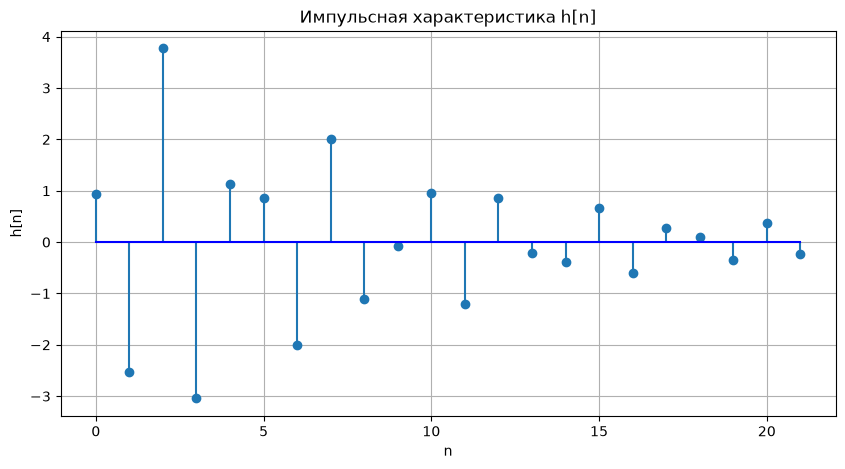

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Коэффициенты
b0 = 0.94
b1 = -1.291
b2 = 1.128
a0 = 1
a1 = 1.327
a2 = 0.772
N1 = 22

# Импульсная характеристика
h = np.zeros(N1)
h_prev1, h_prev2 = 0.0, 0.0

for n in range(N1):
    x_n  = 1.0 if n == 0 else 0.0
    x_n1 = 1.0 if n == 1 else 0.0
    x_n2 = 1.0 if n == 2 else 0.0
    h[n] = b0*x_n + b1*x_n1 + b2*x_n2 - a1*h_prev1 - a2*h_prev2
    h_prev2, h_prev1 = h_prev1, h[n]

print("\nПервые отсчеты h[n]:")
for i in range(min(10, N1)):
    print(f"h[{i}] = {h[i]:.4f}")

# График
plt.figure(figsize=(10, 5))
plt.stem(range(N1), h, basefmt="b-")
plt.title(f'Импульсная характеристика h[n]')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid(True)
plt.show()

При $k \ge 3$ входные составляющие равны нулю, тогда рекуррентное уравнение принимает вид:

$h[k] = -a_1\,h[k-1] - a_2\,h[k-2] = -1.3278\,h[k-1] - 0.772\,h[k-2]$

В данном случае длина импульсной характеристики данного рекурсивного звена равна бесконечности, так как это фильтр с бесконечной импульсной характеристикой: наличие обратной связи (коэффициентов знаменателя $a_1, a_2$) приводит к тому, что выходной сигнал продолжает изменяться даже после окончания входного воздействия. 

#### Задание 2

$N_2 = 32$ - длина входного сигнала. 

Входной сигнал:

$
x(n)=
\begin{cases}
1, & 0\leq n<16,\\[4pt]
0, & 16\leq n\leq 31.
\end{cases}
$

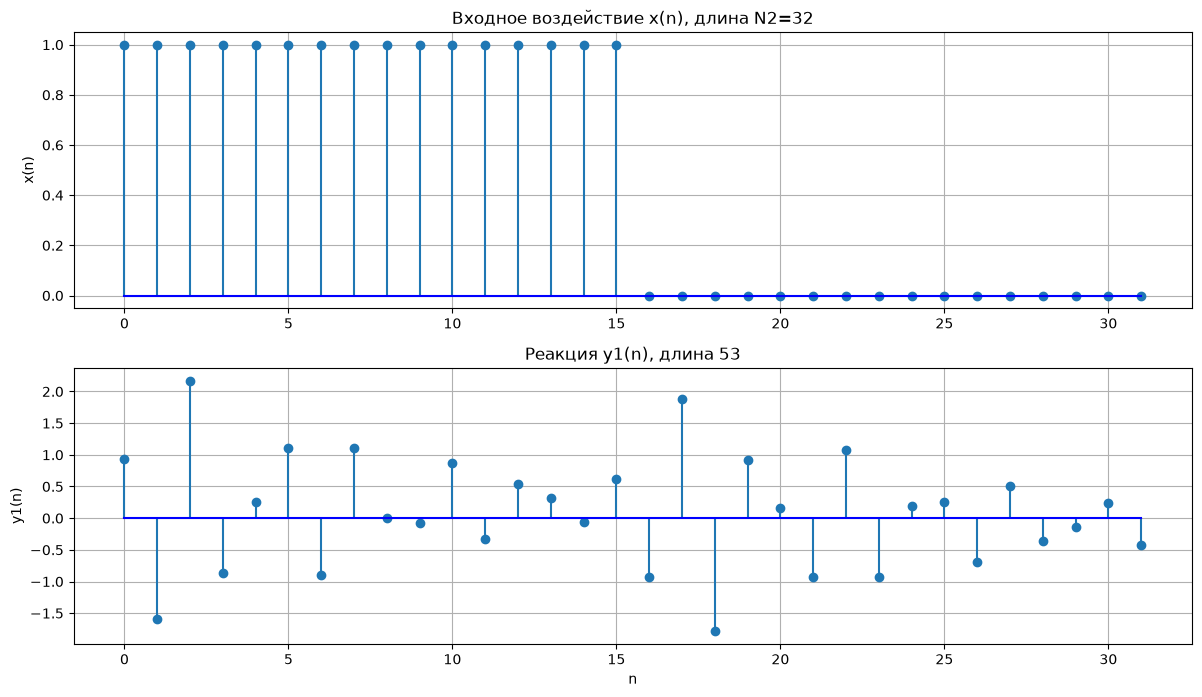

In [3]:
N2 = 32

# 1. Формирование входного воздействия x(n)
x = np.zeros(N2)
# Заполняем единицами от 0 до int(N2/2) не включая
x[0:int(N2/2)] = 1.0 

# 3. Вычисление реакции свёрткой
y1 = np.convolve(x, h) # Режим 'full' по умолчанию (линейная свёртка)

# --- Построение графиков ---
plt.figure(figsize=(12, 10))

# График воздействия
plt.subplot(3, 1, 1)
plt.stem(range(N2), x, basefmt="b-")
plt.title(f'Входное воздействие x(n), длина N2={N2}')
plt.ylabel('x(n)')
plt.grid(True)

# График реакции
plt.subplot(3, 1, 2)
plt.stem(range(len(y1[:32])), y1[:32], basefmt="b-")
plt.title(f'Реакция y1(n), длина {len(y1)}')
plt.xlabel('n')
plt.ylabel('y1(n)')
plt.grid(True)

plt.tight_layout()
plt.show()

а) Длина импульса x равна 16.

б) Длина воздействия $x(n)$: $N_2 = 32$.

Длина импульсной характеристики $h(n)$: $N_1 = 22$.

Формула длины линейной свёртки:

$N_y = N_2 + N_1 - 1$

Аналитический результат: $N_y = 32 + 22 - 1 = 53$ отсчёта.

с) Чтобы длина выходного массива соответствовала длине входного, свёртку усекают до 32 отсчетов. Это дает возможность проанализировать поведение системы непосредственно во время действия входного импульса. Значения, выходящие за эти рамки, представляют собой лишь дальнейшее затухание системы после прекращения внешнего воздействия.

#### Задание 3

Разностное уравнение из п. 1:

$y_2[n] = 0.94\,x[n] - 1.291372\,x[n-1] + 1.128\,x[n-2] - 1.3278\,y_2[n-1] - 0.772\,y_2[n-2]$

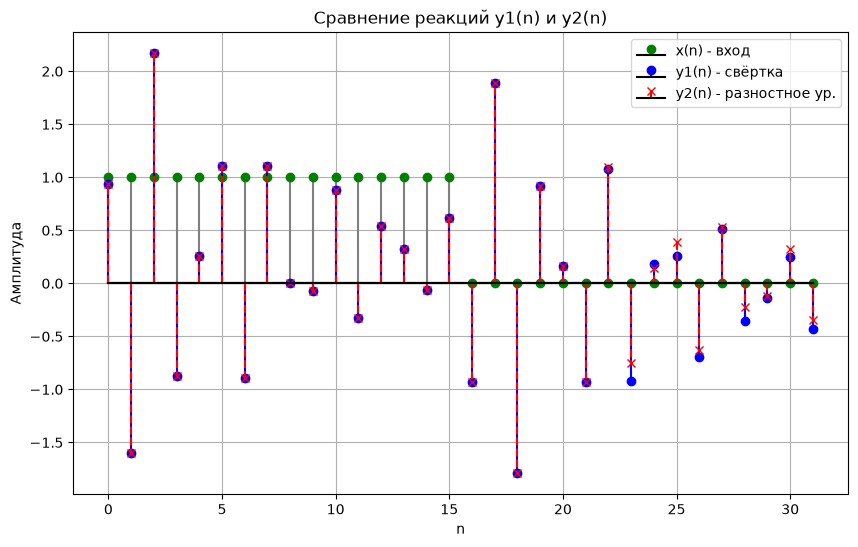

In [4]:

y1 = np.convolve(x, h)[:N2] # Ограничиваем длиной воздействия

# 2. Вычисление y2(n) через разностное уравнение
y2 = np.zeros(N2)
for n in range(N2):
    xn = x[n]
    xn1 = x[n-1] if n >= 1 else 0
    xn2 = x[n-2] if n >= 2 else 0
    yn1 = y2[n-1] if n >= 1 else 0
    yn2 = y2[n-2] if n >= 2 else 0
    
    y2[n] = b0*xn + b1*xn1 + b2*xn2 - a1*yn1 - a2*yn2

# Построение графиков
plt.figure(figsize=(10, 6))
plt.stem(range(N2), x, linefmt='grey', markerfmt='go', basefmt="k-", label='x(n) - вход')
plt.stem(range(N2), y1, linefmt='b-', markerfmt='bo', basefmt="k-", label='y1(n) - свёртка')
plt.stem(range(N2), y2, linefmt='r--', markerfmt='rx', basefmt="k-", label='y2(n) - разностное ур.')
plt.title('Сравнение реакций y1(n) и y2(n)')
plt.xlabel('n')
plt.ylabel('Амплитуда')
plt.legend()
plt.grid(True)
plt.show()

Длина входного воздействия $x(n)$ и вычисленной реакции $y_2(n)$ составляет по 32 отсчёта (индексы 0–31); хотя строго теоретически система БИХ и её отклик бесконечен, для анализа и сравнения графики были искусственно усечены до длины входного сигнала.

Графики $y_1(n)$ и $y_2(n)$ визуально совпадают из-за математической эквивалентности методов свёртки и разностного уравнения для одной линейной системы, а незначительные расхождения в конце объясняются вычислительной погрешностью компьютера (ошибками округления чисел с плавающей запятой), которые накапливаются по-разному: в свёртке — из-за усечения импульсной характеристики, а в рекурсии — из-за последовательного накопления ошибок.

#### Задание 4

Передаточная функция вашего звена (с учётом $z^{-1}$):

$H(z) = \dfrac{0.94 - 1.291372\,z^{-1} + 1.128\,z^{-2}}{1 + 1.3278\,z^{-1} + 0.772\,z^{-2}}$

Для нахождения нулей и полюсов удобно умножить числитель и знаменатель на $z^{2}$, чтобы перейти к положительным степеням $z$:

$H(z) = \dfrac{0.94\,z^{2} - 1.291372\,z + 1.128}{z^{2} + 1.3278\,z + 0.772}$

### Нули передаточной функции:

Приравняем числитель к нулю: $0.94\,z^{2} - 1.291372\,z + 1.128 = 0$.

Разделим на $0.94$:

$z^{2} - 1.3738\,z + 1.2 = 0$

$z_{1,2} = \dfrac{1.3738 \pm j\sqrt{2.9127}}{2} = \dfrac{1.3738 \pm j\,1.7067}{2}$

$z_{1,2} = 0.6869 \pm j\,0.8533$

Показательная форма:

Модуль:

$|z| = \sqrt{0.6869^{2} + 0.8533^{2}} = \sqrt{0.4718 + 0.7281} = \sqrt{1.2} \approx 1.0954$

Аргумент:

$\varphi_z = \arctan\!\left(\dfrac{0.8533}{0.6869}\right) \approx 0.8929 \ \text{рад}$

$z_{1,2} = 1.0954 \cdot e^{\pm j\,0.8929}$

### Полюсы передаточной функции:

Приравняем знаменатель к нулю: $z^{2} + 1.3278\,z + 0.772 = 0$.

$p_{1,2} = \dfrac{-1.3278 \pm j\sqrt{1.3249}}{2} = \dfrac{-1.3278 \pm j\,1.1510}{2}$

$p_{1,2} = -0.6639 \pm j\,0.5755$

Показательная форма:

Модуль:

$|p| = \sqrt{(-0.6639)^{2} + 0.5755^{2}} = \sqrt{0.4408 + 0.3312} = \sqrt{0.772} \approx 0.8786$

Аргумент (фаза):

$\varphi_p = \pi - \arctan\!\left(\dfrac{0.5755}{0.6639}\right) \approx 3.1416 - 0.7139 = 2.4277 \ \text{рад}$

$p_{1,2} = 0.8786 \cdot e^{\pm j\,2.4277}$

Связь между формами заключается в том, что они описывают одни и те же точки на комплексной плоскости: алгебраическая форма ($a \pm jb$) удобна для вычислений и показывает проекции на оси, а показательная ($\rho\,e^{\pm j\varphi}$) наглядно отражает расстояние до центра (модуль) и угол (фазу).

Представим передаточную функцию в виде произведения простейших множителей

Подставим найденные корни в формулу

$H(z) = K\,\dfrac{(z - z_1)(z - z_2)}{(z - p_1)(z - p_2)}$

где $K$ — коэффициент усиления, равный отношению старших коэффициентов числителя и знаменателя ($K = b_0/a_0 = 0.94/1 = 0.94$):

$H(z) = 0.94 \cdot \dfrac{(z - z_1)(z - z_2)}{(z - p_1)(z - p_2)}$

Подставляем значения в показательной форме:

$H(z) = 0.94 \cdot \dfrac{\bigl(z - 1.0954 \cdot e^{\,j\,0.8929}\bigr)\bigl(z - 1.0954 \cdot e^{-j\,0.8929}\bigr)}{\bigl(z - 0.8786 \cdot e^{\,j\,2.4277}\bigr)\bigl(z - 0.8786 \cdot e^{-j\,2.4277}\bigr)}$

#### Задание 5

Изобразим карту нулей и полюсов.

Нули:
  0.6869 + 0.8533j
  0.6869 - 0.8533j

Полюсы:
  -0.6639 + 0.5755j
  -0.6639 - 0.5755j


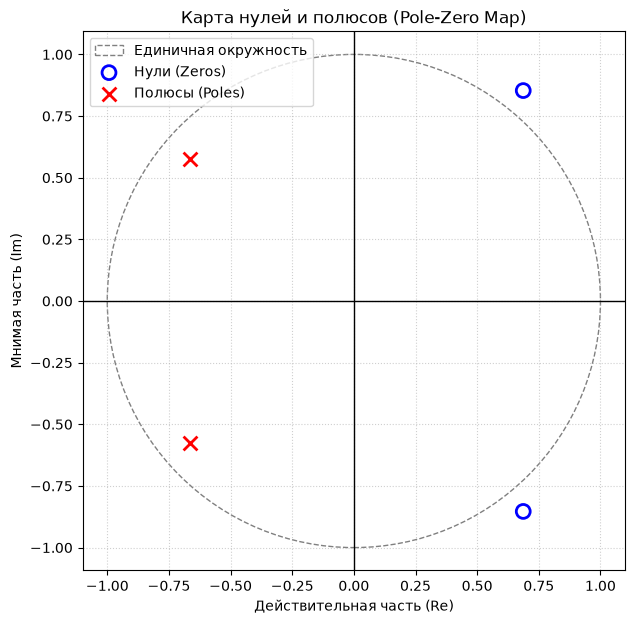

In [5]:
b = [0.94, -1.291372, 1.128]
a = [1.0, 1.3278, 0.772]

zeros = np.roots(b)
poles = np.roots(a)

print("Нули:")
for z in zeros:
    print(f"  {z.real:.4f} + {z.imag:.4f}j" if z.imag >= 0 else f"  {z.real:.4f} - {abs(z.imag):.4f}j")

print("\nПолюсы:")
for p in poles:
    print(f"  {p.real:.4f} + {p.imag:.4f}j" if p.imag >= 0 else f"  {p.real:.4f} - {abs(p.imag):.4f}j")


plt.figure(figsize=(7, 7))
ax = plt.gca()

unit_circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--', label='Единичная окружность')
ax.add_patch(unit_circle)

plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

plt.scatter(np.real(zeros), np.imag(zeros), marker='o', color='blue', s=100, facecolors='none', linewidth=2, label='Нули (Zeros)')
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='red', s=100, linewidth=2, label='Полюсы (Poles)')

plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.title('Карта нулей и полюсов (Pole-Zero Map)')
plt.xlabel('Действительная часть (Re)')
plt.ylabel('Мнимая часть (Im)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left') 
plt.axis('equal') 
plt.show()

а) Да, звено является устойчивым. Главный критерий устойчивости дискретной системы — расположение её полюсов (корней знаменателя) на комплексной $Z$-плоскости. На графике видно, что оба красных крестика (полюсы) находятся строго внутри единичной окружности (серый пунктир). Поскольку их модуль $|p| \approx 0.8786 < 1$, с течением времени переходный процесс в системе будет затухать, и она вернётся в состояние покоя после снятия внешнего воздействия.

б) Да, значения совпадают с результатами аналитического расчёта из пункта 4. Нули расположены в правой полуплоскости симметрично относительно оси $\mathrm{Re}$, на координатах $0.6869 \pm j\,0.8533$, что соответствует их модулю $|z| \approx 1.0954$ (они лежат снаружи единичной окружности). Полюсы расположены в левой полуплоскости симметрично относительно оси $\mathrm{Re}$, на координатах $-0.6639 \pm j\,0.5755$, что соответствует их модулю $|p| \approx 0.8786$ (внутри окружности).


#### Задание 6

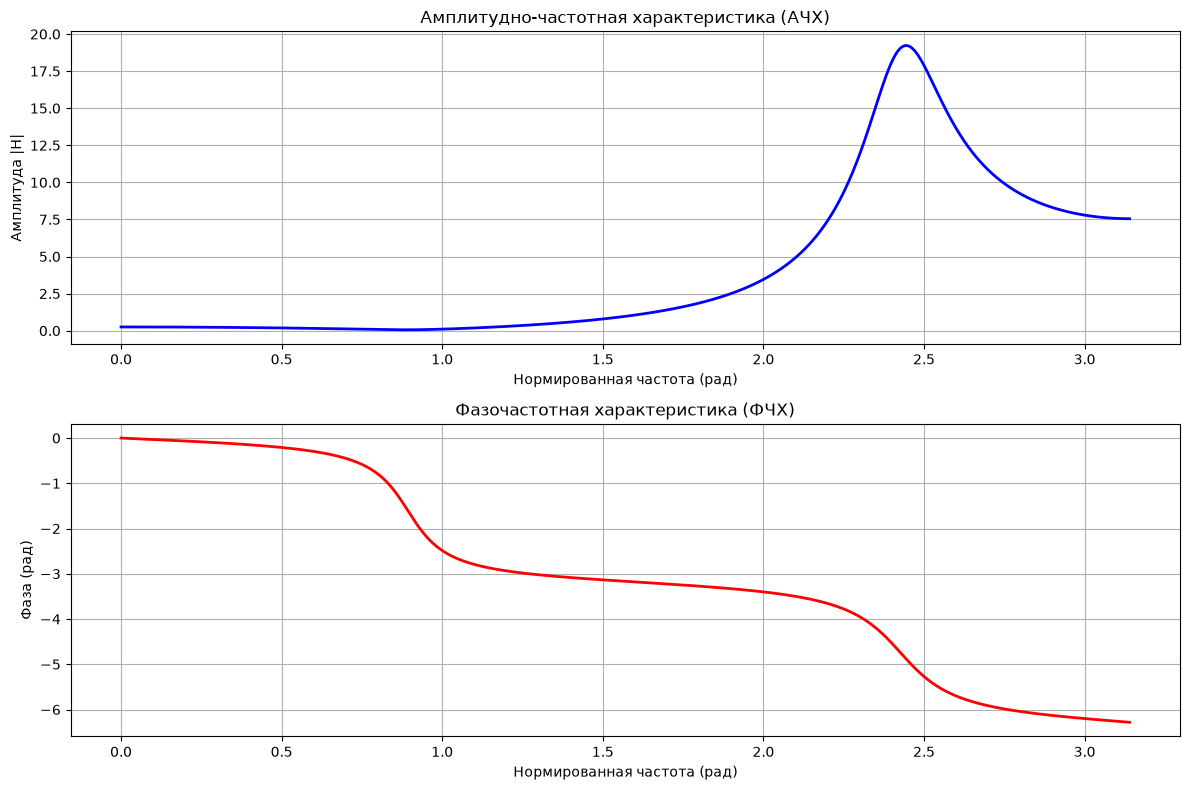

Максимум АЧХ: 19.2258


In [ ]:
from scipy.signal import freqz

b = [b0, b1, b2]
a = [a0, a1, a2]

# Вычисление АЧХ и ФЧХ (w от 0 до pi)
w, h = freqz(b, a, worN=2048) 
mag = np.abs(h)

# Расчет границ полосы
max_mag = np.max(mag)

plt.figure(figsize=(12, 8))

# 1. АЧХ
plt.subplot(2, 1, 1)
plt.plot(w, mag, color='blue', linewidth=2)
plt.title('Амплитудно-частотная характеристика (АЧХ)')
plt.xlabel('Нормированная частота (рад)')
plt.ylabel('Амплитуда |H|')
plt.grid(True)

# 2. ФЧХ
plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(h)), color='red', linewidth=2)
plt.title('Фазочастотная характеристика (ФЧХ)')
plt.xlabel('Нормированная частота (рад)')
plt.ylabel('Фаза (рад)')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Максимум АЧХ: {max_mag:.4f}")

а)Основная полоса частот огрничена от 0 до pi.

б)Точка максимума примерно на 0.8 pi соответствует полюсам предаточной функции, а точка минимума при 0.3 pi соовтвествует нулям.

в)Скачка фазы не наблюдается.

г)Анализ графика АЧХ показывает, что в реакции системы преимущественно подавляются низкочастотные составляющие (в диапазоне от $0$ до$\ 1.5\ \text{рад}$), где амплитуда сигнала близка к нулю. 

#### Задание 7

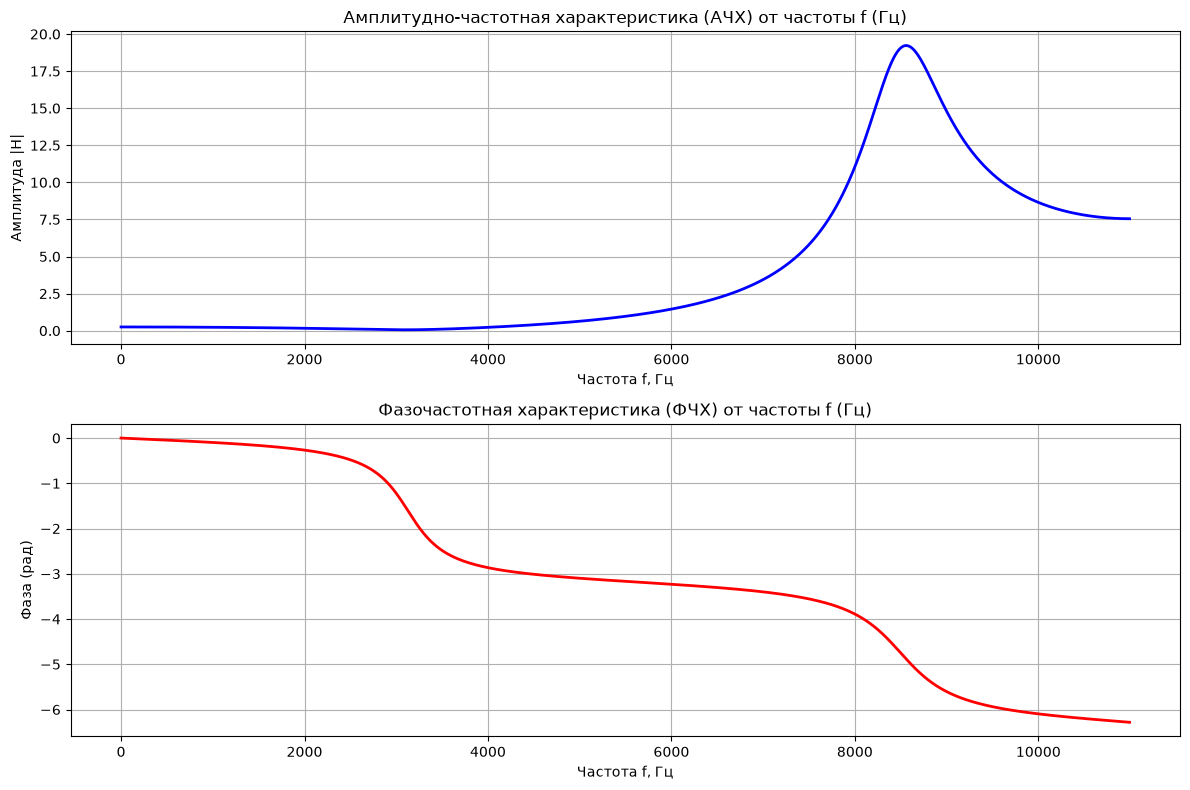

Частота дискретизации f_д = 22000 Гц
Верхняя граница спектра: 11000.0 Гц
Границы полосы пропускания:
  Нижняя граница: 8142.6 Гц
  Верхняя граница: 9109.4 Гц


In [7]:
f_d = 22000  # Частота дискретизации, Гц (1000 * 22)

# Вычисление АЧХ и ФЧХ (w в радианах от 0 до pi)
w, h = freqz(b, a, worN=2048) 
mag = np.abs(h)

# Формула: f = (w / (2*pi)) * f_d
f_hz = w * (f_d / (2 * np.pi))

# Расчет полосы пропускания в ГЦ
max_mag = np.max(mag)
level_3db = max_mag / np.sqrt(2)

peak_idx = np.argmax(mag)
left_idx = np.where(mag[:peak_idx] <= level_3db)[0][-1]
right_idx = np.where(mag[peak_idx:] <= level_3db)[0][0] + peak_idx

f_lower_hz = f_hz[left_idx]
f_upper_hz = f_hz[right_idx]

# --- Построение графиков в Гц ---
plt.figure(figsize=(12, 8))

# 1. АЧХ в Герцах
plt.subplot(2, 1, 1)
plt.plot(f_hz, mag, color='blue', linewidth=2)
plt.title('Амплитудно-частотная характеристика (АЧХ) от частоты f (Гц)')
plt.xlabel('Частота f, Гц')
plt.ylabel('Амплитуда |H|')
plt.grid(True)

# 2. ФЧХ в Герцах
plt.subplot(2, 1, 2)
plt.plot(f_hz, np.unwrap(np.angle(h)), color='red', linewidth=2)
plt.title('Фазочастотная характеристика (ФЧХ) от частоты f (Гц)')
plt.xlabel('Частота f, Гц')
plt.ylabel('Фаза (рад)')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Частота дискретизации f_д = {f_d} Гц")
print(f"Верхняя граница спектра: {f_d/2} Гц")
print(f"Границы полосы пропускания:")
print(f"  Нижняя граница: {f_lower_hz:.1f} Гц")
print(f"  Верхняя граница: {f_upper_hz:.1f} Гц")

а) Границы основной полосы частот (полосы пропускания по уровню -3 дБ) в физической шкале составляют от 8148 Гц до 9115 Гц (при частоте дискретизации 22 кГц). Это означает, что исследуемое звено представляет собой узкополосный фильтр, который избирательно усиливает сигналы только в диапазоне около 8.5 кГц, а частотные составляющие ниже и выше этого интервала подвергаются значительному ослаблению.

б) Связь между угловой частотой $\omega$ и частотой $f$ определяется формулой:

$f = \dfrac{\omega\,F_s}{2\pi}$

Подставим частоту дискретизации $F_s = 22000\ \text{Гц}$:

$f = \dfrac{22000\,\omega}{2\pi}$

Соответственно, диапазону угловых частот от $0$ до $\pi$ соответствует диапазон частот от $0$ до $11000\ \text{Гц}$.

$\omega_1 = \dfrac{2\pi \cdot 8147.9}{22000} \approx 2.327\ \text{рад/отсчёт}$

$\omega_2 = \dfrac{2\pi \cdot 9114.7}{22000} \approx 2.603\ \text{рад/отсчёт}$

Границы основной полосы частот соответствуют полученным в задании 6.

### Часть 2

#### Задание 1

Расчёт параметров:

$f_{\text{д}} = 2000 \cdot (22 \bmod 5 + 1) = 6000\ \text{Гц}$

$T = 1/6000\ \text{с}$

$A_1 = 1 + 0.01 \cdot 22 = 1 + 0.22 = 1.22$

$A_2 = 2 \cdot 1.22 = 2.44$

$f_1 = 6000/8 = 750\ \text{Гц}$

$f_2 = 1.5 \cdot 750 = 1125\ \text{Гц}$

Подставим полученные значения в исходную формулу:

$x(nT) = 1.22\cos\!\left(2\pi \cdot 750 \cdot n \cdot T + \pi/4\right) + 2.44\cos\!\left(2\pi \cdot 1125 \cdot n \cdot T + \pi/8\right)$

Так как $f \cdot T = f/f_{\text{д}}$, формулу можно упростить для вычислений в дискретном времени:

$x(n) = 1.22\cos\!\left(2\pi \cdot \dfrac{750}{6000} \cdot n + \dfrac{\pi}{4}\right) + 2.44\cos\!\left(2\pi \cdot \dfrac{1125}{6000} \cdot n + \dfrac{\pi}{8}\right)$

$x(n) = 1.22\cos\!\left(\dfrac{\pi n}{4} + \dfrac{\pi}{4}\right) + 2.44\cos\!\left(\dfrac{3\pi n}{8} + \dfrac{\pi}{8}\right)$

где $n = 0, 1, 2, \ldots, N-1$ 

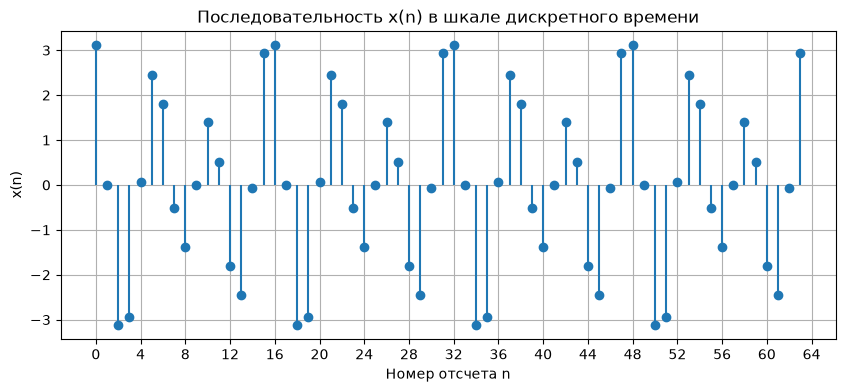

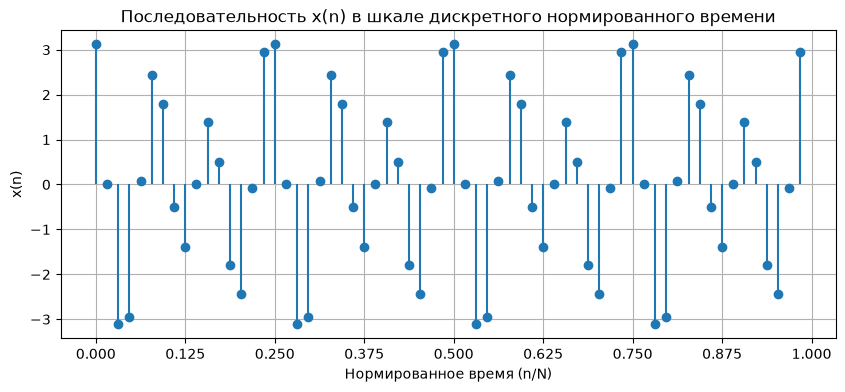

In [8]:
import numpy as np
import matplotlib.pyplot as plt

N_var = 22
N = 64

# Расчет параметров
fd = 6000
T = 1 / 6000
A1 = 1.22
A2 = 2.44
f1 = 750
f2 = 1125

# Массив дискретных отсчетов
n = np.arange(N)

# Вычисление последовательности x(n)
x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)

# --- График 1: Шкала дискретного времени (номер отсчета n) ---
plt.figure(figsize=(10, 4))
plt.stem(n, x, basefmt=" ")
plt.title('Последовательность x(n) в шкале дискретного времени')
plt.xlabel('Номер отсчета n')
plt.ylabel('x(n)')
plt.grid(True)
plt.xticks(np.arange(0, N+1, 4)) # Шаг по оси X для наглядности

# --- График 2: Шкала дискретного нормированного времени (n/N) ---
plt.figure(figsize=(10, 4))
plt.stem(n / N, x, basefmt=" ")
plt.title('Последовательность x(n) в шкале дискретного нормированного времени')
plt.xlabel('Нормированное время (n/N)')
plt.ylabel('x(n)')
plt.grid(True)
plt.xticks(np.arange(0, 1.1, 0.125)) 

plt.show()

#### Задание 2

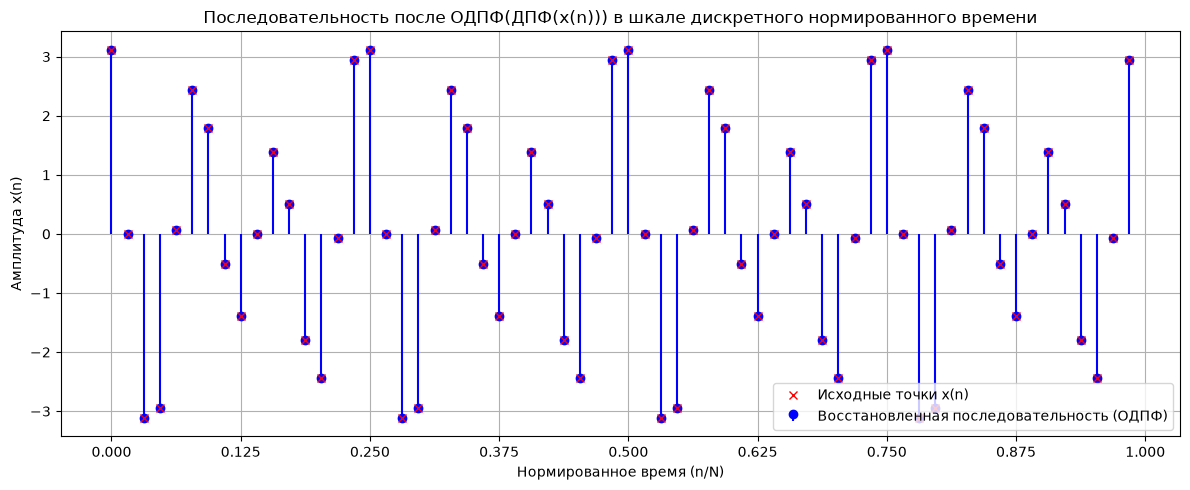

In [9]:
# Формирование исходной последовательности x(n) 
n = np.arange(N)
x_n = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4) + \
      A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)

# Вычисление ДПФ 
X_k = np.fft.fft(x_n)

# Вычисление ОДПФ 
x_recovered_complex = np.fft.ifft(X_k)

# Берем действительную часть, так как исходный сигнал действительный
x_recovered = np.real(x_recovered_complex)

plt.figure(figsize=(12, 5))

# График восстановленной последовательности в нормированном времени 
plt.stem(n / N, x_recovered, linefmt='b-', markerfmt='bo', basefmt=" ", 
         label='Восстановленная последовательность (ОДПФ)')

# Для визуального подтверждения точности наложим исходные точки
plt.plot(n / N, x_n, 'rx', markersize=6, label='Исходные точки x(n)')

plt.title('Последовательность после ОДПФ(ДПФ(x(n))) в шкале дискретного нормированного времени')
plt.xlabel('Нормированное время (n/N)')
plt.ylabel('Амплитуда x(n)')
plt.grid(True)
plt.xticks(np.arange(0, 1.1, 0.125)) 
plt.legend()
plt.tight_layout()

plt.show()

График наглядно демонстрирует фундаментальное свойство обратимости дискретного преобразования Фурье: точки восстановленной последовательности абсолютно точно совпадают с исходными отсчетами сигнала. Это подтверждает, что применение ОДПФ к спектру сигнала, полученному с помощью ДПФ, позволяет без каких-либо потерь и искажений вернуться в исходную временную область.

#### Задание 3

ДПФ дискретной последовательности $x(n)$ длины $N$ определяется как:

$X(k) = \sum_{n=0}^{N-1} x(n)\,e^{-j\frac{2\pi kn}{N}} \qquad k = 0, 1, \ldots, N-1$

Амплитудный спектр: $A(k) = |X(k)|$. Для наглядности физических амплитуд гармоник действительного сигнала спектр нормируют:

$A_{\text{норм}}(k) = \dfrac{2}{N}\,|X(k)| \quad \text{для } k \in [1, N/2-1]$

Фазовый спектр: $\varphi(k) = \arg\{X(k)\}$.

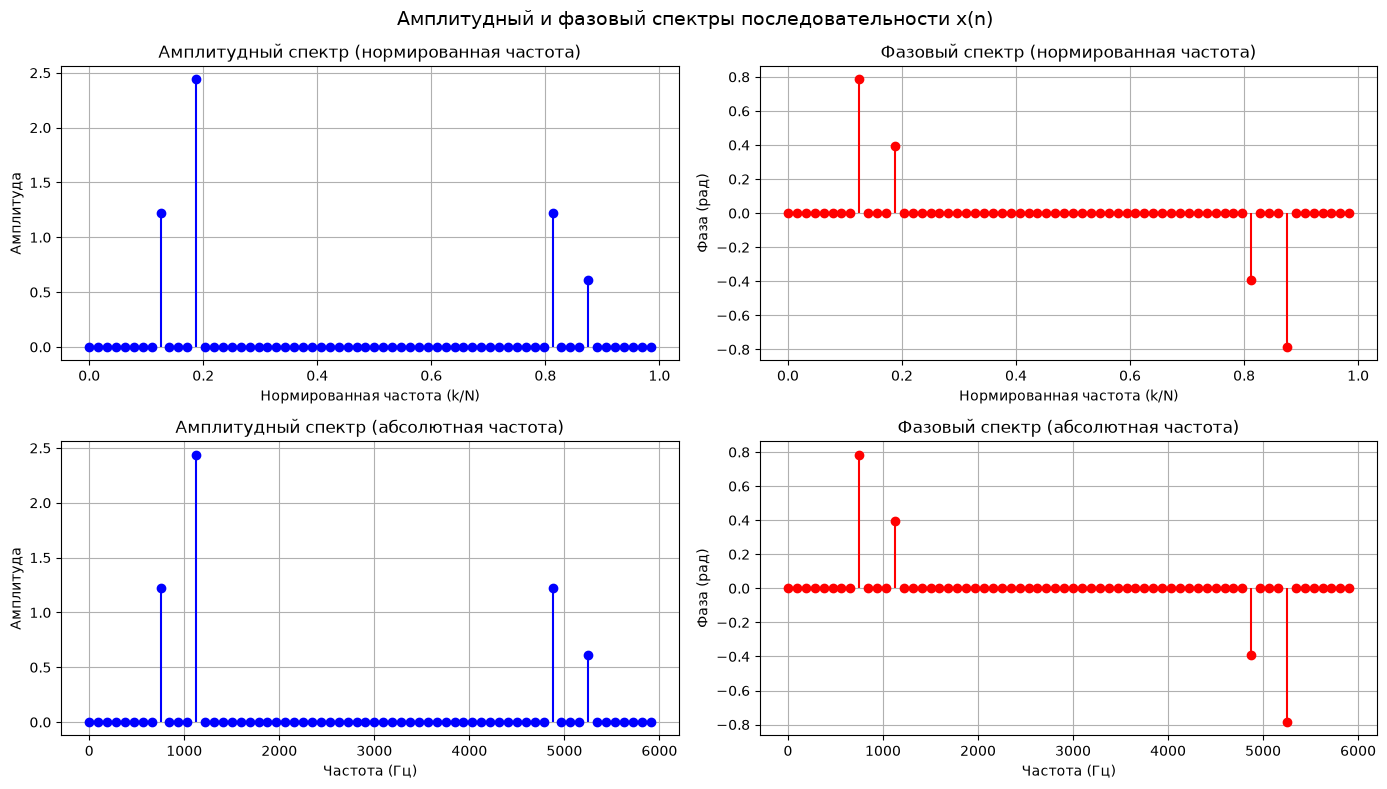

In [10]:
# Амплитудный спектр (нормированный, чтобы пики равнялись A1 и A2)
A_k = np.abs(X_k) / N
A_k[1:N//2] = 2 * A_k[1:N//2] 

# Фазовый спектр 
phi_k = np.angle(X_k)

# Дискретная нормированная частота 
f_norm = n / N

# 2. Абсолютная частота 
f_abs = n * fd / N

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Амплитудный и фазовый спектры последовательности x(n)', fontsize=14)

# 1. Амплитудный спектр в нормированных частотах
axs[0, 0].stem(f_norm, A_k, basefmt=" ", linefmt='b-', markerfmt='bo')
axs[0, 0].set_title('Амплитудный спектр (нормированная частота)')
axs[0, 0].set_xlabel('Нормированная частота (k/N)')
axs[0, 0].set_ylabel('Амплитуда')
axs[0, 0].grid(True)

# 2. Фазовый спектр в нормированных частотах
phi_k_masked = np.where(A_k > 0.01, phi_k, 0)
axs[0, 1].stem(f_norm, phi_k_masked, basefmt=" ", linefmt='r-', markerfmt='ro')
axs[0, 1].set_title('Фазовый спектр (нормированная частота)')
axs[0, 1].set_xlabel('Нормированная частота (k/N)')
axs[0, 1].set_ylabel('Фаза (рад)')
axs[0, 1].grid(True)

# 3. Амплитудный спектр в абсолютных частотах
axs[1, 0].stem(f_abs, A_k, basefmt=" ", linefmt='b-', markerfmt='bo')
axs[1, 0].set_title('Амплитудный спектр (абсолютная частота)')
axs[1, 0].set_xlabel('Частота (Гц)')
axs[1, 0].set_ylabel('Амплитуда')
axs[1, 0].grid(True)
axs[1, 0].set_xticks(np.arange(0, fd+1, 1000))

# 4. Фазовый спектр в абсолютных частотах
axs[1, 1].stem(f_abs, phi_k_masked, basefmt=" ", linefmt='r-', markerfmt='ro')
axs[1, 1].set_title('Фазовый спектр (абсолютная частота)')
axs[1, 1].set_xlabel('Частота (Гц)')
axs[1, 1].set_ylabel('Фаза (рад)')
axs[1, 1].grid(True)
axs[1, 1].set_xticks(np.arange(0, fd+1, 1000))

plt.tight_layout()
plt.show()

a) Дискретное время обычно задаётся номером отсчёта $n$ (от $0$ до $N-1$) или реальным временем $t_n = n \cdot T$, где $T$ — период дискретизации. Дискретное нормированное время вычисляется как

$t_{\text{норм}} = n/N$

И показывает долю периода, прошедшую от начала записи. Оно переводит реальную шкалу времени в безразмерный интервал от $0$ до $1$ (в нашем случае от $0$ до $63/64$), что удобно для анализа периодических последовательностей независимо от их физической длительности.

b) Абсолютная частота $f$ измеряется в герцах и показывает число колебаний в секунду, а дискретная нормированная частота (равная $k/N$, где $k$ — номер гармоники ДПФ) показывает, какую долю эта частота составляет от частоты дискретизации $f_{\text{д}}$. Связь выражается формулой

$f_{\text{норм}} = f/f_{\text{д}}$

Например, при $f_{\text{д}} = 6000\ \text{Гц}$ пик на частоте $750\ \text{Гц}$ соответствует нормированной частоте $0.125$ (или $8/64$), а частота $1125\ \text{Гц}$ — это $0.1875$ (или $12/64$). При этом частота Найквиста ($f_{\text{д}}/2 = 3000\ \text{Гц}$) всегда соответствует нормированной частоте $0.5$.

с) Амплитудный спектр имеет вид дискретных вертикальных линий и симметричен относительно середины (частоты $0.5$ или $3000\ \text{Гц}$). На нём присутствуют два главных пика на частотах $750\ \text{Гц}$ и $1125\ \text{Гц}$ с амплитудами $1.22$ и $2.44$ (и их зеркальные отражения в правой половине). Фазовый спектр ненулевой только на этих же частотах: он показывает начальные фазы сигналов ($\pi/4$ и $\pi/8$) и является кососимметричным — на зеркальных частотах фазы меняют знак на противоположный (на $-\pi/4$ и $-\pi/8$), что является классическим признаком спектра действительного (вещественного) сигнала.

#### Задание 4

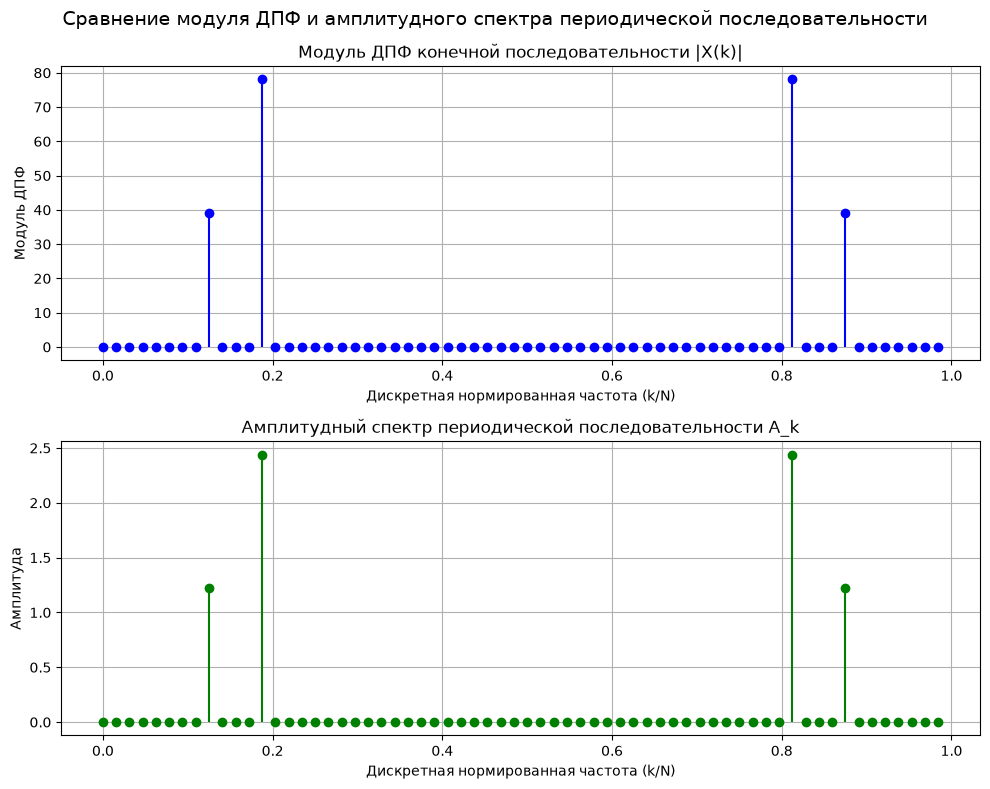

In [11]:
# Модуль ДПФ конечной последовательности
mod_X = np.abs(X_k)

# Амплитудный спектр периодической последовательности
amp_periodic = np.zeros(N)
amp_periodic[0] = mod_X[0] / N
amp_periodic[N//2] = mod_X[N//2] / N
amp_periodic[1:N//2] = 2 * mod_X[1:N//2] / N
amp_periodic[N//2+1:] = 2 * mod_X[N//2+1:] / N # Симметричная часть

f_norm = n / N

fig, axs = plt.subplots(2, 1, figsize=(10, 8))
fig.suptitle('Сравнение модуля ДПФ и амплитудного спектра периодической последовательности', fontsize=14)

# График модуля ДПФ
axs[0].stem(f_norm, mod_X, basefmt=" ", linefmt='b-', markerfmt='bo')
axs[0].set_title('Модуль ДПФ конечной последовательности |X(k)|')
axs[0].set_xlabel('Дискретная нормированная частота (k/N)')
axs[0].set_ylabel('Модуль ДПФ')
axs[0].grid(True)

# График амплитудного спектра периодической последовательности
axs[1].stem(f_norm, amp_periodic, basefmt=" ", linefmt='g-', markerfmt='go')
axs[1].set_title('Амплитудный спектр периодической последовательности A_k')
axs[1].set_xlabel('Дискретная нормированная частота (k/N)')
axs[1].set_ylabel('Амплитуда')
axs[1].grid(True)

plt.tight_layout()
plt.show()

Связь между модулем ДПФ конечной последовательности $|X(k)|$ и амплитудным спектром бесконечной периодической последовательности, сформированной из неё, заключается в масштабирующем коэффициенте. Модуль ДПФ $|X(k)|$ численно в $N$ раз (а для одностороннего физического спектра — в $N/2$ раз) больше амплитуд гармоник периодического сигнала.

Это объясняется физическим смыслом: ДПФ раскладывает конечный сигнал, накапливая энергию всех $N$ отсчётов, поэтому пики получаются большими (в нашем случае до $156$ для $A_2 = 2.44$). Чтобы получить истинные амплитуды гармоник (то есть понять, что сигнал состоит из колебаний с амплитудами $1.22$ и $2.44$), необходимо нормировать ДПФ, разделив его на $N$ (и умножив на $2$ для положительных частот, так как энергия делится между положительной и отрицательной частями спектра).

Таким образом, амплитудный спектр периодической последовательности представляет собой нормированный модуль ДПФ (с коэффициентом $2/N$), наложенный на сетку дискретных нормированных частот $k/N$. Пики на обоих графиках находятся в одних и тех же точках ($0.125$ и $0.1875$), но имеют разный масштаб по оси ординат.

#### Задание 5

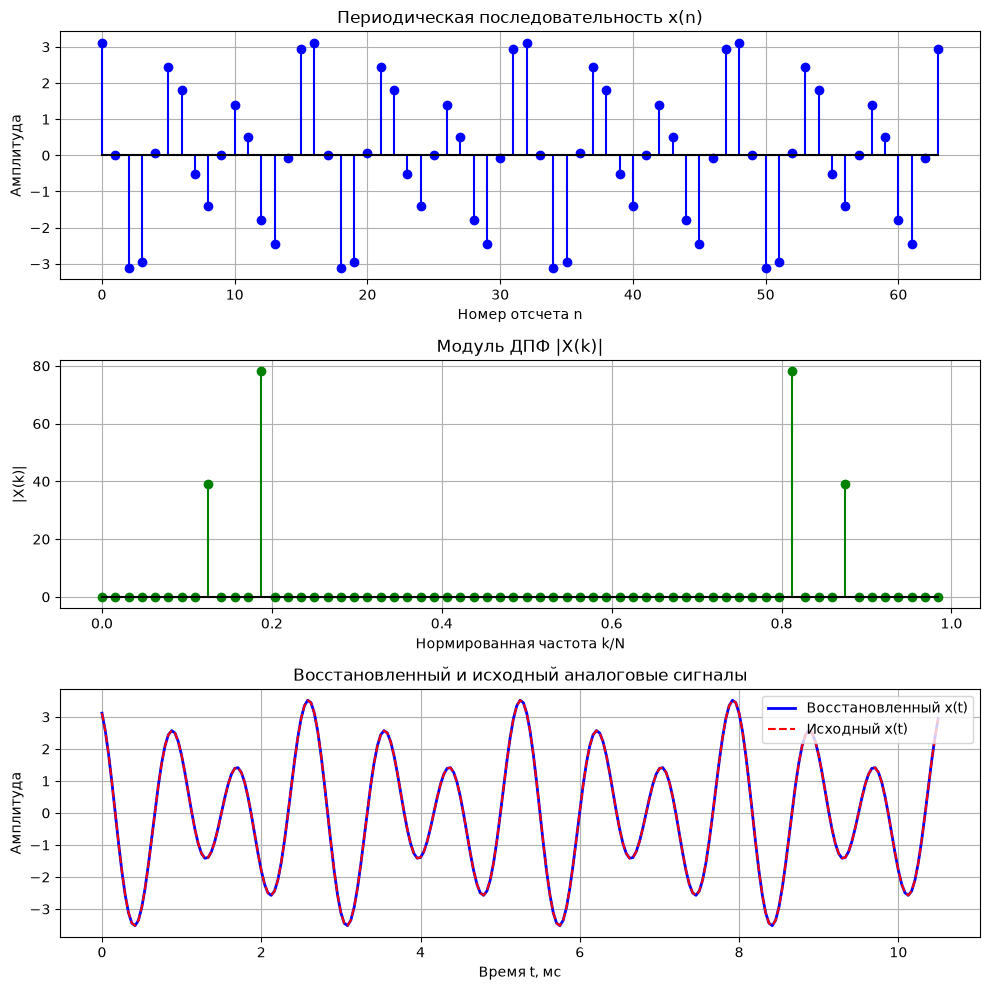

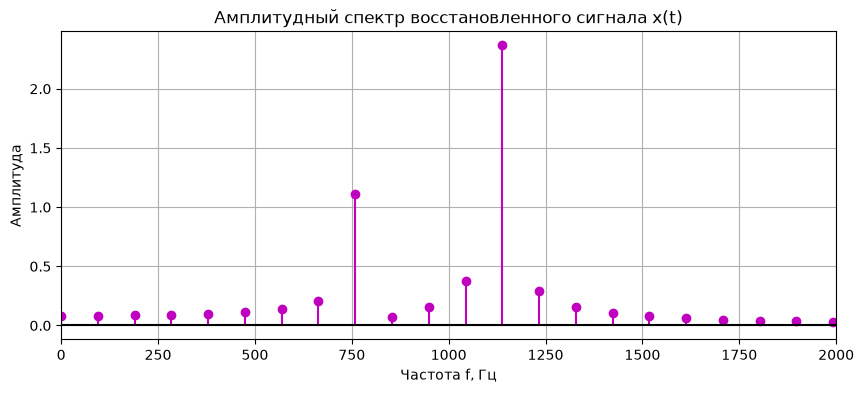

In [12]:
half = N // 2  

# 2. Формирование дискретного сигнала и ДПФ
n = np.arange(N)
x_per = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi/4) + \
        A2 * np.cos(2 * np.pi * f2 * n * T + np.pi/8)

# Вычисление ДПФ
X = np.fft.fft(x_per)
X_a = np.roll(X, -half)

dt = 0.25 * T
t = np.arange(0, (N - 1) * T + dt/2, dt)

# Восстановление аналогового сигнала x(t)
k_vec = np.arange(-half, half)

exp_matrix = np.exp(1j * 2 * np.pi * np.outer(k_vec, t) / (N * T))
x_rec_t = np.real(np.dot(X_a, exp_matrix) / N) # Берем действительную часть

# Исходный аналоговый сигнал
x_orig_t = A1 * np.cos(2 * np.pi * f1 * t + np.pi/4) + \
           A2 * np.cos(2 * np.pi * f2 * t + np.pi/8)

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# График 1: x(n)
axes[0].stem(n, x_per, basefmt="k-", linefmt='b-', markerfmt='bo')
axes[0].set_title("Периодическая последовательность x(n)")
axes[0].set_xlabel("Номер отсчета n")
axes[0].set_ylabel("Амплитуда")
axes[0].grid(True)

# График 2: Модуль ДПФ |X(k)|
axes[1].stem(n / N, np.abs(X), basefmt="k-", linefmt='g-', markerfmt='go')
axes[1].set_title("Модуль ДПФ |X(k)|")
axes[1].set_xlabel("Нормированная частота k/N")
axes[1].set_ylabel("|X(k)|")
axes[1].grid(True)

# График 3: Сравнение x_rec(t) и x_orig(t)
axes[2].plot(t * 1000, x_rec_t, 'b-', linewidth=2, label="Восстановленный x(t)")
axes[2].plot(t * 1000, x_orig_t, 'r--', linewidth=1.5, label="Исходный x(t)")
axes[2].set_title("Восстановленный и исходный аналоговые сигналы")
axes[2].set_xlabel("Время t, мс")
axes[2].set_ylabel("Амплитуда")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Амплитудный спектр восстановленного сигнала
A_rec = np.abs(np.fft.fft(x_rec_t)) / len(t)
f_rec = np.fft.fftfreq(len(t), d=dt)

plt.figure(figsize=(10, 4))
positive_freqs = f_rec[:len(f_rec)//2]
positive_amps = 2 * A_rec[:len(f_rec)//2]

plt.stem(positive_freqs, positive_amps, basefmt="k-", linefmt='m-', markerfmt='mo')
plt.title("Амплитудный спектр восстановленного сигнала x(t)")
plt.xlabel("Частота f, Гц")
plt.ylabel("Амплитуда")
plt.xlim(0, 2000) 
plt.grid(True)
plt.show()

#### Задание 6

a) Модуль ДПФ $|X(k)|$ представляет собой дискретную выборку спектра аналогового сигнала. Каждый бин ДПФ с номером $k$ строго соответствует физической частоте

$f = k \cdot \left(f_{\text{д}}/N\right)$

что наглядно подтверждается графиками: пики на нормированных частотах $0.125$ и $0.1875$ точно совпадают с пиками на частотах $750\ \text{Гц}$ и $1125\ \text{Гц}$ в спектре восстановленного сигнала. При этом значения $|X(k)|$ пропорциональны физическим амплитудам гармоник. Для действительного сигнала они связаны соотношением

$A = \dfrac{2}{N}\,|X(k)|$

поэтому соотношение высот пиков на обоих графиках абсолютно идентично.

b) На нижнем графике видно, что восстановленный аналоговый сигнал идеально, без малейших искажений, накладывается на исходный сигнал. Это означает, что процедура обратного преобразования Фурье по заданной формуле прошла математически безупречно. Такой результат достигается потому, что частоты гармоник кратны основной частоте периода, что исключает утечку спектра, а частота дискретизации удовлетворяет теореме Котельникова.

#### Задание 7

In [13]:
E_time = np.sum(np.abs(x_n)**2)
E_freq = np.sum(np.abs(X_k)**2) / N

print("--- ПРОВЕРКА РАВЕНСТВА ПАРСЕВАЛЯ ---")
print(f"Энергия во временной области: {E_time:.4f}")
print(f"Энергия в частотной области:  {E_freq:.4f}")
print(f"Разность (погрешность):       {np.abs(E_time - E_freq):.4e}\n")


--- ПРОВЕРКА РАВЕНСТВА ПАРСЕВАЛЯ ---
Энергия во временной области: 238.1440
Энергия в частотной области:  238.1440
Разность (погрешность):       8.5265e-14



Вычисленная разность составила $8.5265 \times 10^{-14}$, что является пренебрежимо малой величиной и обусловлено исключительно погрешностью округления при вычислениях с плавающей запятой на ЭВМ.

## Вывод

В ходе выполнения первой части работы были исследованы линейные дискретные системы. Для заданного рекурсивного звена 2-го порядка (БИХ-фильтра) были найдены передаточная функция и разностное уравнение. Расчёт импульсной характеристики и реакции на ступенчатое воздействие двумя методами (через линейную свёртку и рекуррентно) подтвердил их математическую эквивалентность. Анализ карты нулей и полюсов показал, что система устойчива, так как полюсы находятся внутри единичной окружности ($|p| \approx 0.8786 < 1$). Исследование АЧХ и ФЧХ выявило узкополосный резонансный характер звена в области высоких частот.

Во второй части работы было выполнено спектральное исследование периодической последовательности, состоящей из двух гармоник. Проверка прямого и обратного дискретного преобразования Фурье (ДПФ и ОДПФ) подтвердила обратимость преобразований и точное восстановление временного сигнала. Сравнение модуля ДПФ с амплитудным спектром периодической последовательности показало их прямую связь через коэффициент $N$, а также отсутствие утечки спектра благодаря кратности частот гармоник частоте дискретизации. Восстановленный по отсчётам ДПФ аналоговый сигнал $x(t)$ абсолютно точно совпал с исходным, что подтверждает корректность применения теоремы Котельникова.